# Fan Chart (forecast uncertainty)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Shows observed history followed by a forecast drawn as nested bands of uncertainty that widen over time. It shows the best guess together with honest uncertainty about it.

## When to use

- Show forecasts or projections with confidence or prediction intervals
- Show that uncertainty grows with the forecast horizon
- Present model outputs to decision-makers (inflation, demand, epidemics)

## Avoid when

- The intervals have no statistical basis (they would imply false precision)
- The audience will read the central line as a promise

## Alternatives

- Line with a single confidence band
- Spaghetti plot of scenarios

## Design tips

- Use one hue with increasing transparency for wider intervals
- Mark clearly where observations end and forecasts begin

## Example

Monthly demand (synthetic): 4 years of history plus a 12-month forecast with 50/80/95% intervals.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
from scipy import stats
rng = np.random.default_rng(9)
hist_dates = pd.date_range("2021-01", periods=48, freq="MS")
hist = 200 + 2 * np.arange(48) + 15 * np.sin(np.arange(48) * 2 * np.pi / 12) + rng.normal(0, 6, 48)
fc_dates = pd.date_range(hist_dates[-1], periods=13, freq="MS")
h = np.arange(13)
center = hist[-1] + 2 * h + 15 * (np.sin((48 + h - 1) * 2 * np.pi / 12) - np.sin(47 * 2 * np.pi / 12))
sd = 4.2 * np.sqrt(h)          # zero at the last observation, growing with the horizon
bands = {lvl: (center - stats.norm.ppf(0.5 + lvl / 2) * sd, center + stats.norm.ppf(0.5 + lvl / 2) * sd)
         for lvl in (0.5, 0.8, 0.95)}
forecast = pd.DataFrame({"date": fc_dates, "center": center, "sd": sd})
forecast.head()

,date,center,sd
0,2024-12-01,297.783794,0.000000
1,2025-01-01,307.283794,4.200000
2,2025-02-01,316.783794,5.939697
3,2025-03-01,324.274175,7.274613
4,2025-04-01,328.283794,8.400000


### Plot

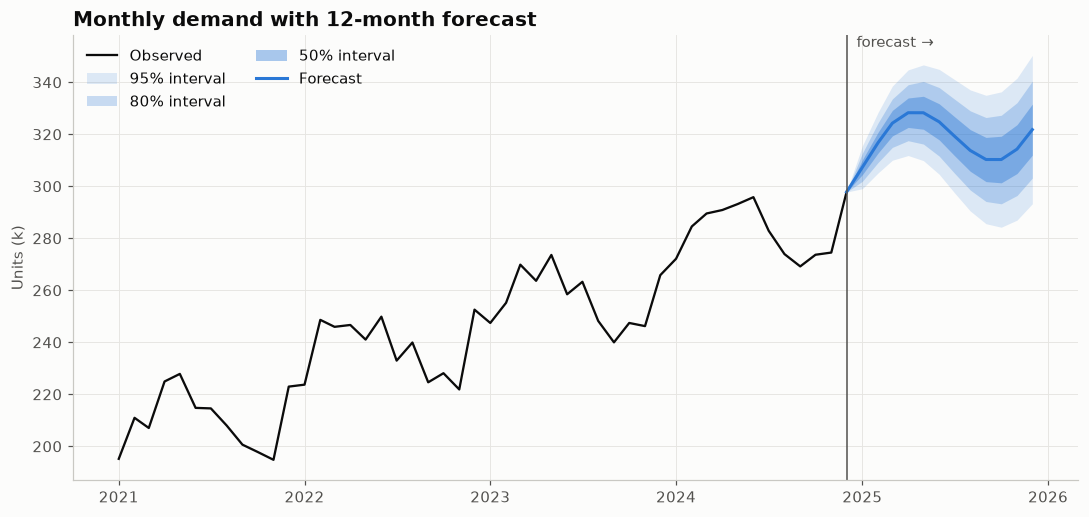

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(hist_dates, hist, color="#0b0b0b", linewidth=1.5, label="Observed")
for lvl, alpha in [(0.95, 0.15), (0.8, 0.25), (0.5, 0.4)]:
    lo, hi = bands[lvl]
    ax.fill_between(fc_dates, lo, hi, color=PALETTE[0], alpha=alpha, linewidth=0,
                    label=f"{int(lvl * 100)}% interval")
ax.plot(fc_dates, center, color=PALETTE[0], linewidth=2, label="Forecast")
ax.axvline(hist_dates[-1], color="#52514e", linewidth=1)
ax.text(hist_dates[-1], ax.get_ylim()[1], "  forecast →", va="top", color="#52514e")
ax.set_ylabel("Units (k)")
ax.set_title("Monthly demand with 12-month forecast")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

## How to read it

The dark line is history and the blue line the central forecast. The darkest band holds a 50% chance of the outcome and the lightest band 95%.

---
Standalone script: [`fan_chart.py`](fan_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)